# NFC VHBR アップリンク BER カーブ（ADP3250 ツインコイルブリッジ）

`2026_nfc_vhbr_ber` で測った BER を、このフォルダの CSV だけから描き直すノートブック。
CSV は `make_csv.py` が `../2026_nfc_vhbr_ber/results` の JSON から作る（測り直したら作り直す）。

| 図 | CSV | 内容 |
|---|---|---|
| 1 | `e05_fcN_183.csv` | e05、位相 183°、FC/32〜FC/4 の比較 |
| 2 | `fc8_183_series.csv` | FC/8、位相 183°、整合系列 e05〜e70 の比較 |
| 3〜8 | `phase_e20.csv` 〜 `phase_e70.csv` | FC/8、系列ごとの位相補正（183° と補正後と位相のずれ） |

CSV の列：`series, div, rate_mbps, phase_deg, role, date, level_dbm, bits, errors, ber, frames, expected, note`。
`role` は `default`（既定 183°）/ `corrected`（補正後）/ `sweep`（位相のずれ）/ `original`（差し替える前の値）/ `175.53`（旧既定値）。

共通の条件：W1+W2 駆動、600 ビットのフレーム、誤り訂正なし。各点は誤り 100 個以上かつ 60 万ビット以上、または 1e7 ビットまで
（低いレベルは 150〜300 秒で打ち切り）。描き方：1e-5 未満は 1e-5 に置いて白抜きの下向き三角、取得フレーム 100 枚未満は白抜き（参考値）。

In [1]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt

DATA = Path(".")          # このノートブックと同じフォルダ (data/)
FLOOR = 1e-5
# 日本語が出るフォントを、入っているものから 1 つ選ぶ（Windows / macOS / Linux）
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
_jp = [n for n in ("Yu Gothic", "Meiryo", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic") if n in _have]
plt.rcParams["font.family"] = _jp[:1] or ["sans-serif"]
plt.rcParams["axes.unicode_minus"] = False


NUM = {"div": int, "rate_mbps": float, "phase_deg": float, "level_dbm": float,
       "bits": int, "errors": int, "ber": float, "frames": int, "expected": int}


def load(name):
    """CSV を行の dict のリストで読む（数値の列は数値にする）。pandas なら pd.read_csv(DATA / name) でも同じ。"""
    with open(DATA / name, encoding="utf-8") as f:
        return [{k: NUM[k](v) if k in NUM else v for k, v in r.items()} for r in csv.DictReader(f)]


def pick(rows, **cond):
    return [r for r in rows if all(r[k] == v for k, v in cond.items())]


def uniq(rows, key):
    return list(dict.fromkeys(r[key] for r in rows))


def curve(ax, rows, color, ls="-", lw=1.8, marker="o", ms=5, label=None, z=3, alpha=1.0):
    """1 本の BER カーブ。1e-5 未満は 1e-5 に置いて白抜き下向き三角、frames < 100 は白抜き。"""
    rows = sorted(rows, key=lambda r: r["level_dbm"])
    x = [r["level_dbm"] for r in rows]
    y = [max(r["ber"], FLOOR) for r in rows]
    ax.plot(x, y, ls, marker=marker, color=color, lw=lw, ms=ms, label=label, zorder=z, alpha=alpha)
    for r, yy in zip(rows, y):
        if r["frames"] < 100:
            ax.plot(r["level_dbm"], yy, marker, ms=ms + 3, mfc="white", mec=color, mew=1.6, zorder=6)
        if r["ber"] < FLOOR:
            ax.plot(r["level_dbm"], FLOOR, "v", ms=11, mfc="white", mec=color, mew=1.6, zorder=6)


def frame(ax, title):
    ax.set_yscale("log"); ax.set_ylim(7e-6, 1); ax.set_xlim(-31.5, 15.5); ax.set_xticks(range(-30, 15, 2))
    ax.axhline(1e-3, color="gray", ls=":", lw=1.2); ax.text(-30, 1.3e-3, "BER 1e-3", color="gray", fontsize=10)
    ax.axhline(FLOOR, color="crimson", ls="--", lw=1.2, alpha=0.8)
    ax.text(-30, 1.2e-5, "1e-5（これ以下は 1e-5 として扱う）", color="crimson", fontsize=10)
    ax.grid(True, which="major", alpha=0.35); ax.grid(True, which="minor", alpha=0.12)
    ax.set_xlabel("AWG 設定レベル [dBm]（+10 dBm = 1 V peak）"); ax.set_ylabel("BER")
    ax.set_title(title + "\n白い下向き三角 = 1e-5 未満、白抜き = 取得フレーム 100 枚未満の参考値", fontsize=11)

## 図 1　e05：データレート（FC/N）の比較、位相 183°

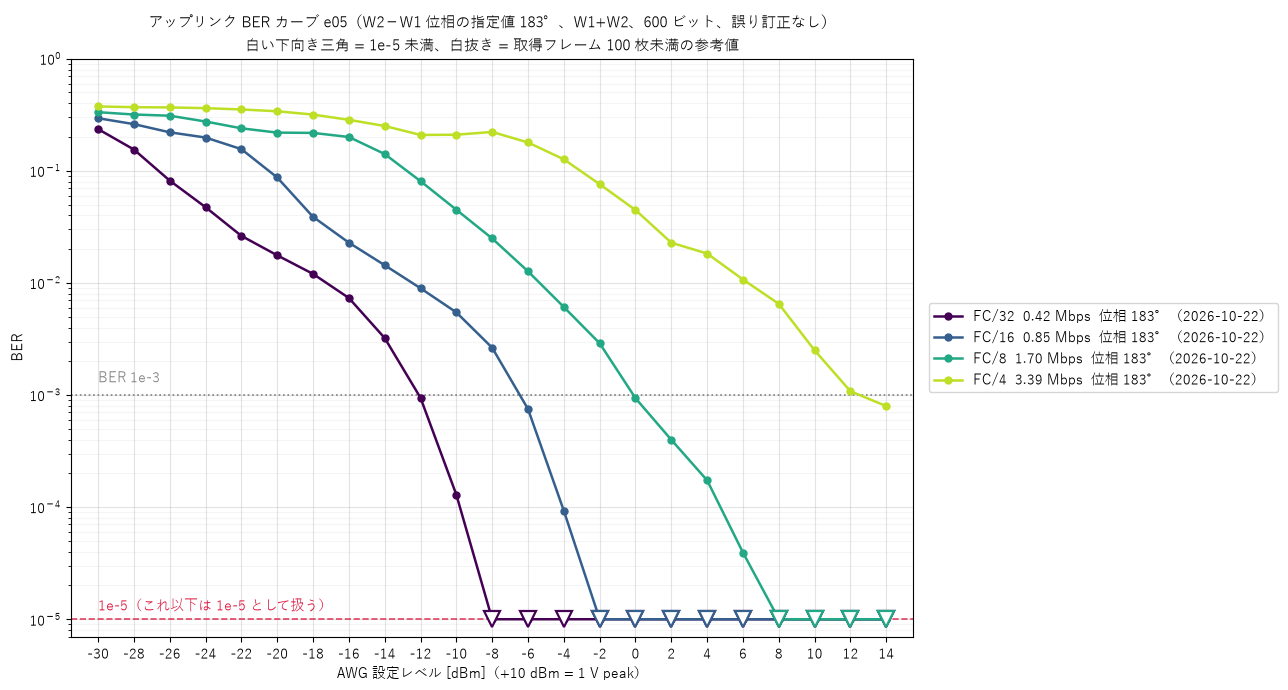

In [2]:
df = load("e05_fcN_183.csv")
fig, ax = plt.subplots(figsize=(13, 7))
cmap = plt.get_cmap("viridis")
for i, div in enumerate(uniq(df, "div")):
    g = pick(df, div=div)
    curve(ax, g, cmap(i / 3 * 0.9), label=f"FC/{div}  {g[0]['rate_mbps']:.2f} Mbps  位相 183°（{g[0]['date']}）")
frame(ax, "アップリンク BER カーブ e05（W2−W1 位相の指定値 183°、W1+W2、600 ビット、誤り訂正なし）")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=10)
fig.tight_layout(); plt.show()

## 図 2　FC/8・位相 183°：整合系列 e05〜e70 の比較

e50 の −20〜+14 dBm は 10/26、e60 の −20〜+14 dBm は 10/27（タグ貼り直し後）の再測定値。

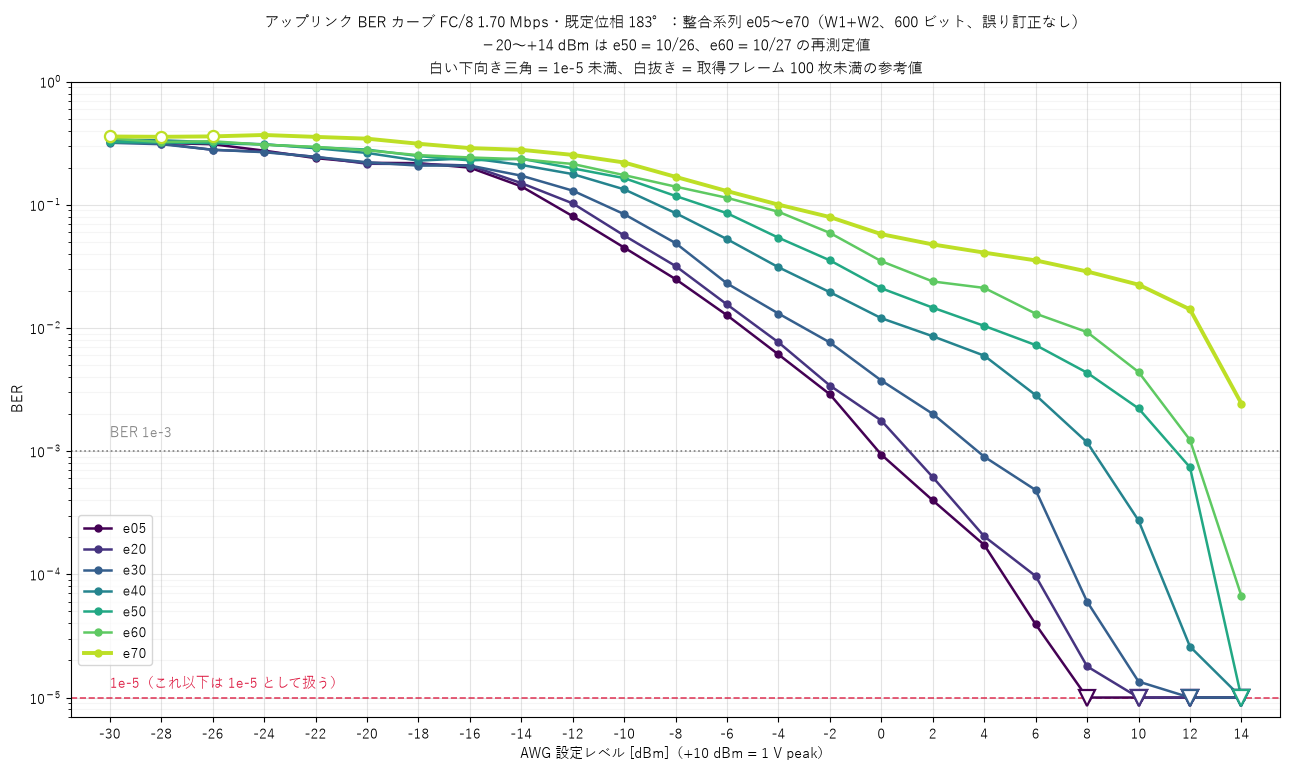

In [3]:
df = load("fc8_183_series.csv")
names = uniq(df, "series")
fig, ax = plt.subplots(figsize=(13, 7.8))
cmap = plt.get_cmap("viridis")
for i, s in enumerate(names):
    curve(ax, pick(df, series=s), cmap(i / (len(names) - 1) * 0.9), lw=2.8 if s == names[-1] else 1.8, label=s)
frame(ax, "アップリンク BER カーブ FC/8 1.70 Mbps・既定位相 183°：整合系列 e05〜e70（W1+W2、600 ビット、誤り訂正なし）\n"
          "−20〜+14 dBm は e50 = 10/26、e60 = 10/27 の再測定値")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.07), fontsize=10)
fig.tight_layout(); plt.show()

## 図 3〜8　系列ごとの位相補正（FC/8）

灰色の実線 = 既定 183°（補正前）、黒の太い実線 = 補正後、色付きの破線 = 位相のずれ。
e20 の灰色の一点鎖線は旧既定値 175.53°（10/20）、e40 の黒の点線は補正後 202° の 0〜+10 dBm を測り直す前の値。

In [4]:
def phase_plot(series, note=""):
    df = load(f"phase_{series}.csv")
    sw = [r["phase_deg"] for r in df if r["role"] in ("sweep", "corrected")]
    lo, hi = min(sw), max(sw)
    cmap = plt.get_cmap("turbo")
    fig, ax = plt.subplots(figsize=(13, 7.8))
    for ph in sorted(uniq(df, "phase_deg")):
        for role in uniq(pick(df, phase_deg=ph), "role"):
            g = pick(df, phase_deg=ph, role=role)
            date = g[-1]["date"]
            if role == "default":
                curve(ax, g, "0.6", lw=2.8, z=4, label=f"位相 {ph:g}°（既定）")
            elif role == "corrected":
                curve(ax, g, "black", lw=3.2, ms=7, z=5, label=f"位相 {ph:g}°（補正後）")
            elif role == "original":
                curve(ax, g, "black", ls=":", lw=1.4, ms=0, marker="o", z=2, label=f"位相 {ph:g}°（差し替え前の値）")
            elif role == "175.53":
                curve(ax, g, "0.7", ls="-.", lw=1.5, marker="s", z=2, label=f"位相 {ph:g}°（旧既定、{date}）")
            else:
                c = cmap(0.08 + 0.84 * (ph - lo) / (hi - lo))
                curve(ax, g, c, ls="--", lw=1.5, marker="s", label=f"位相 {ph:g}°")
    cor = pick(df, role="corrected")[0]["phase_deg"]
    frame(ax, f"アップリンク BER カーブ {series} FC/8 1.70 Mbps：W2−W1 位相の指定値ごと（W1+W2、600 ビット、誤り訂正なし）\n"
              f"灰色の実線 = 既定 183°、黒の太い実線 = 補正後 {cor:g}°、破線 = 位相のずれ {lo:g}〜{hi:g}°" + (f"　{note}" if note else ""))
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
    fig.tight_layout(); plt.show()

### e20

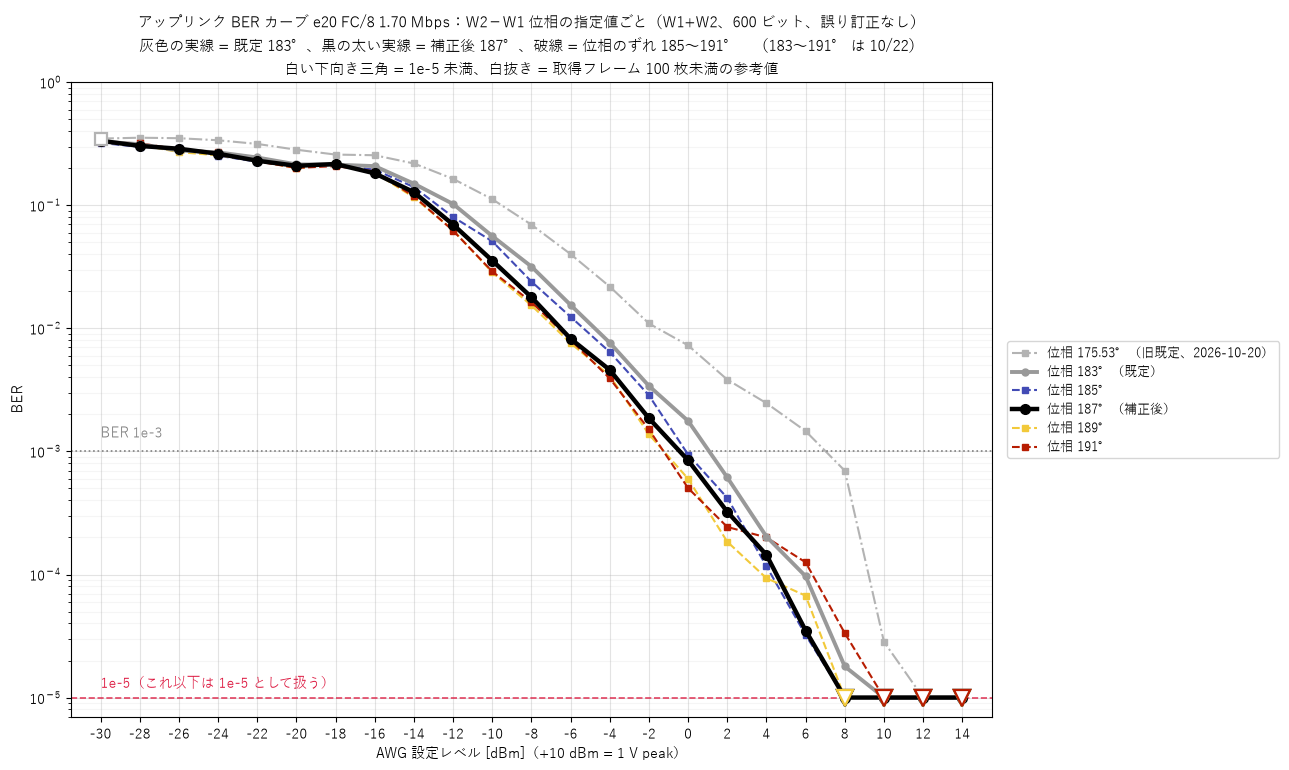

In [5]:
phase_plot("e20", "（183〜191° は 10/22）")

### e30

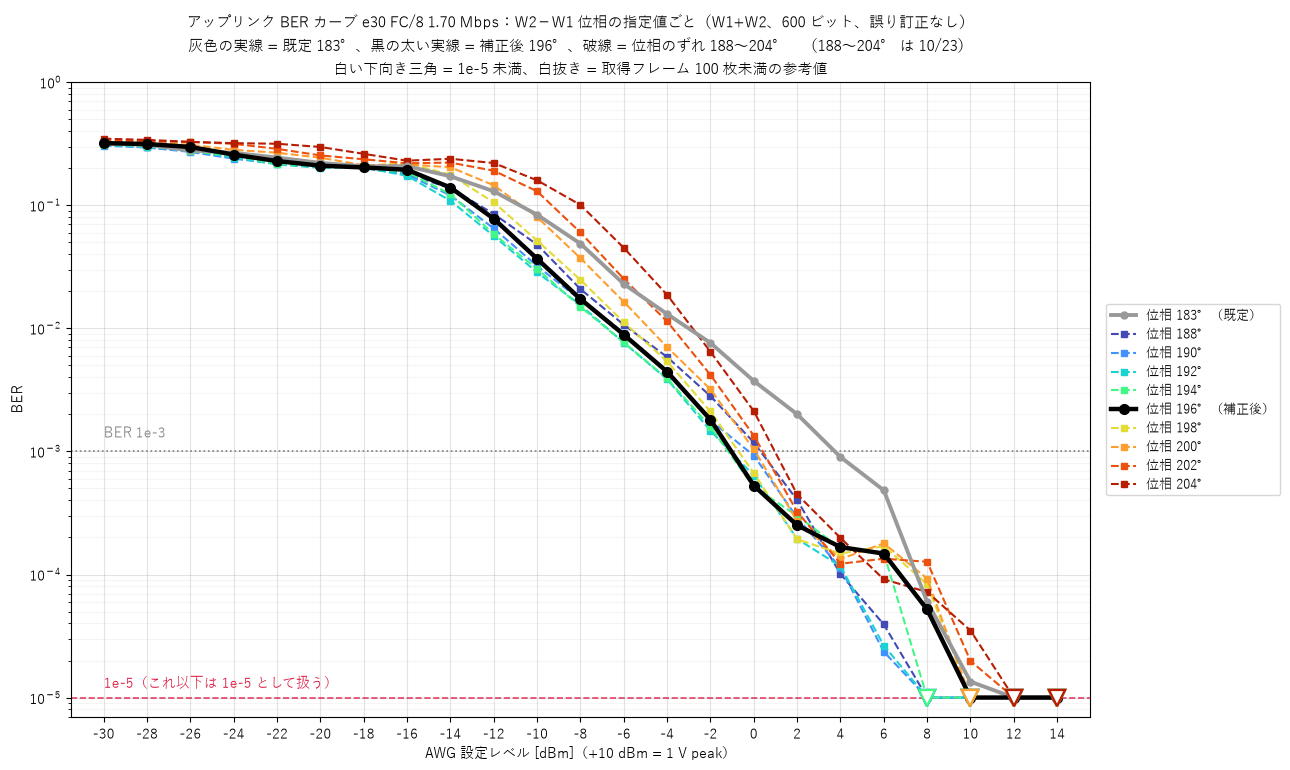

In [6]:
phase_plot("e30", "（188〜204° は 10/23）")

### e40

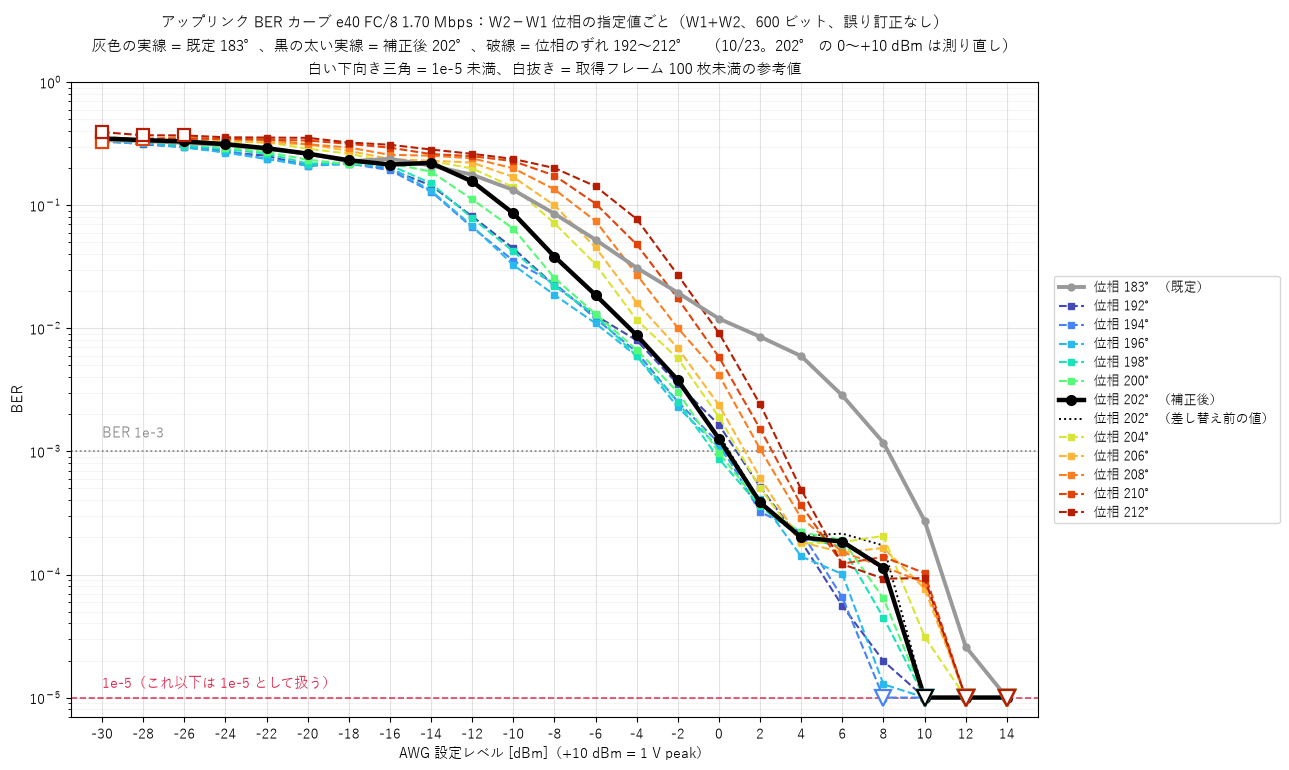

In [7]:
phase_plot("e40", "（10/23。202° の 0〜+10 dBm は測り直し）")

### e50

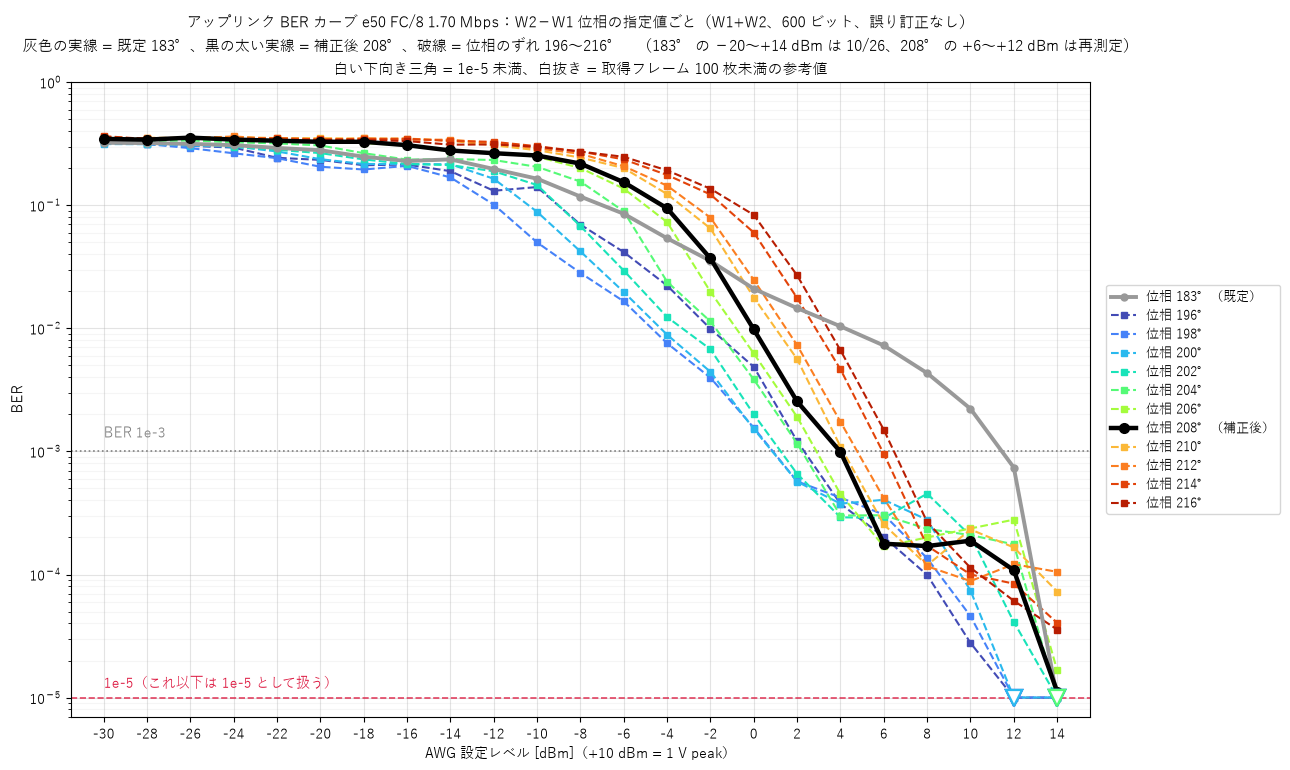

In [8]:
phase_plot("e50", "（183° の −20〜+14 dBm は 10/26、208° の +6〜+12 dBm は再測定）")

### e60

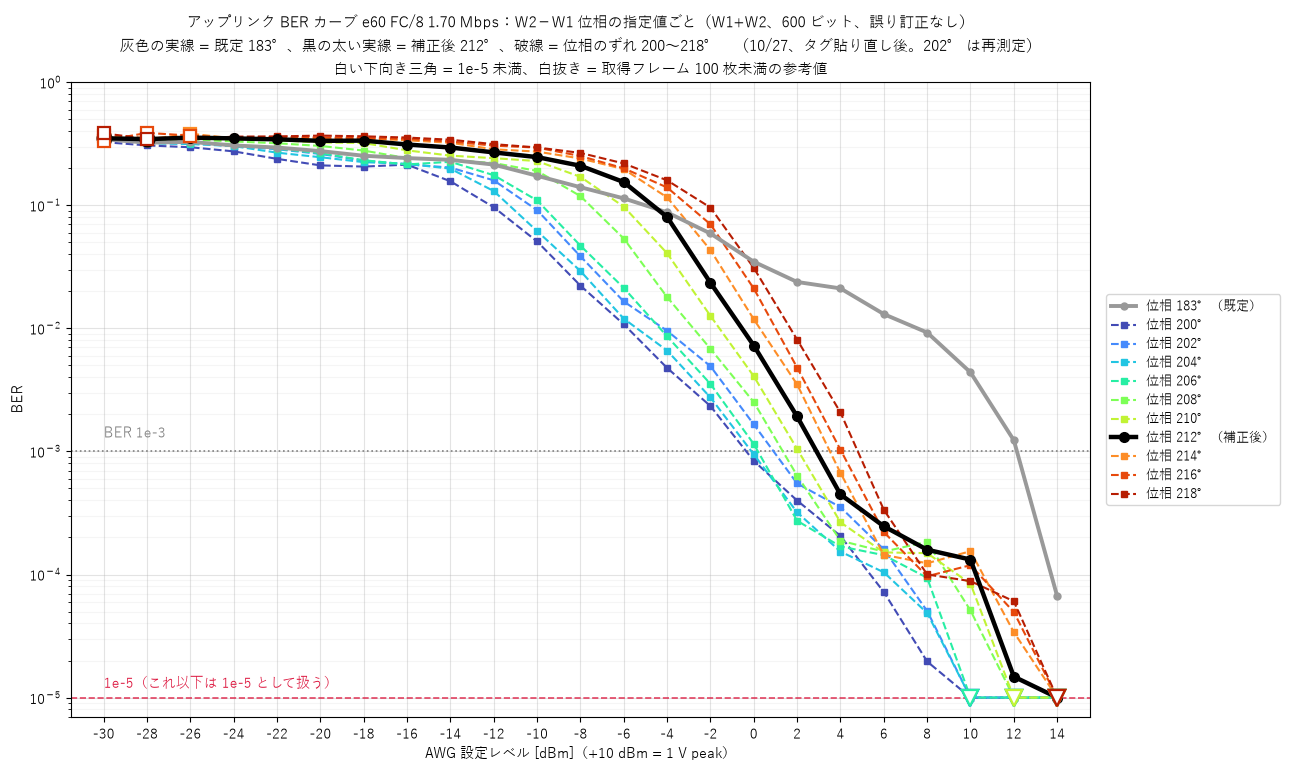

In [9]:
phase_plot("e60", "（10/27、タグ貼り直し後。202° は再測定）")

### e70

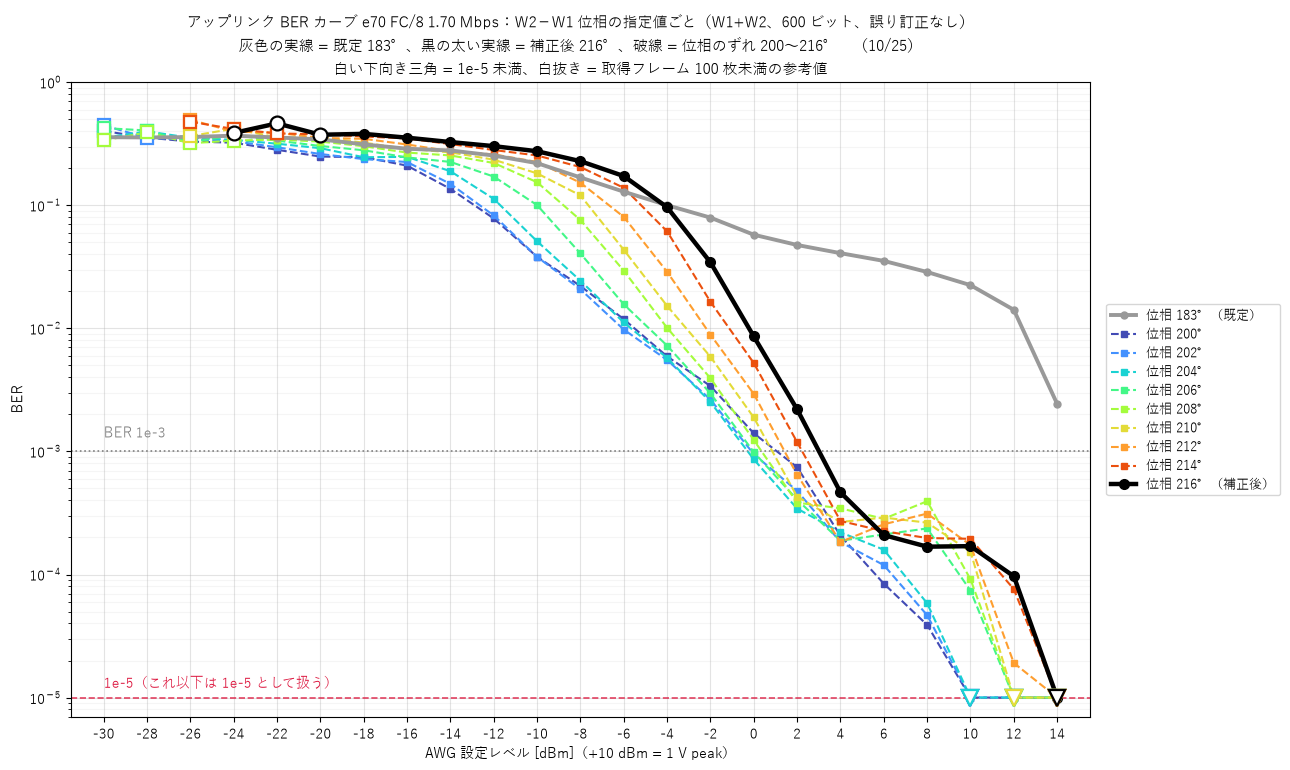

In [10]:
phase_plot("e70", "（10/25）")